# CSCI218 Group Project: Optimizing Last-Mile Delivery Routes Using Genetic Algorithms
**Topic 9: Travelling Salesman Problem (TSP)**

### Overview
Delivery platforms like Talabat regularly assign multiple customer drop-offs to a single driver in one trip. Finding the shortest route between all stops is a classic Travelling Salesman Problem (TSP)—as the number of stops grows, checking every possible path becomes computationally impossible.

In this notebook, we use delivery coordinates from `talabat_enhanced_orders.csv` (a synthetic, Talabat-inspired dataset from Kaggle; see the README for the source) to build a **Genetic Algorithm (GA)** that finds near-optimal delivery routes. We compare its distance and execution time against two baselines:
* **Brute-Force Search** (exact optimal route for small stop counts)
* **Greedy Nearest-Neighbor** (fast heuristic baseline)




*Step 1: Setup and Data downloading*

In [1]:
import itertools
import random
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Keep results reproducible across runs
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Relative path: the CSV sits next to this notebook (repo folder locally, /content in Colab)
raw_df = pd.read_csv("talabat_enhanced_orders.csv")

# Filter for Cairo orders and grab 14 drop-offs + 1 driver starting point (15 stops total)
SELECTED_CITY = "Cairo"
NUM_DROPOFFS = 14

city_orders = raw_df[raw_df["City"] == SELECTED_CITY].reset_index(drop=True)
sample_orders = city_orders.iloc[:NUM_DROPOFFS]

# Node 0 is where the driver starts; Nodes 1-14 are customer locations
locations = [{
    "ID": 0,
    "Label": f"Driver Start (Order #{sample_orders.loc[0, 'Order_ID']})",
    "lat": sample_orders.loc[0, "Driver_Lat"],
    "lon": sample_orders.loc[0, "Driver_Lon"],
}]

for idx, row in sample_orders.iterrows():
  locations.append({
      "ID": idx + 1,
      "Label": f"Order #{row['Order_ID']} ({row['Item_Name']})",
      "lat": row["Customer_Lat"],
      "lon": row["Customer_Lon"],
  })

nodes_df = pd.DataFrame(locations)


def haversine(lat1, lon1, lat2, lon2):
  # Straight-line distance in km between two lat/lon points on Earth
  R = 6371.0
  dlat = np.radians(lat2 - lat1)
  dlon = np.radians(lon2 - lon1)
  a = (
      np.sin(dlat / 2) ** 2
      + np.cos(np.radians(lat1))
      * np.cos(np.radians(lat2))
      * np.sin(dlon / 2) ** 2
  )
  return 2 * R * np.arcsin(np.sqrt(a))


# Build an N x N matrix storing distances between every pair of stops
coords = nodes_df[["lat", "lon"]].values
n = len(coords)
dist_matrix = np.zeros((n, n))

for i in range(n):
  for j in range(n):
    if i != j:
      dist_matrix[i][j] = haversine(
          coords[i][0], coords[i][1], coords[j][0], coords[j][1]
      )


def route_distance(tour, matrix):
  # Total loop distance starting and returning to Node 0
  dist = sum(matrix[tour[i]][tour[i + 1]] for i in range(len(tour) - 1))
  return dist + matrix[tour[-1]][tour[0]]


print(f"Loaded {n} stops in {SELECTED_CITY}.")
nodes_df.head()

Loaded 15 stops in Cairo.


,ID,Label,lat,lon
0,0,Driver Start (Order #7),30.038769,31.231835
1,1,Order #7 (Sushi),30.043525,31.233372
2,2,Order #10 (Pizza),30.025107,31.229281
3,3,Order #15 (Burger),30.031402,31.225295
4,4,Order #22 (Pizza),30.041003,31.220671


*Step 2: Baseline Algorithms (Brute-Force & Greedy)*

In [2]:
def brute_force_tsp(matrix):
  # Checks every possible permutation; only practical for ~10 or fewer stops
  start = time.perf_counter()
  other_stops = list(range(1, len(matrix)))
  best_tour, min_dist = None, float("inf")

  for perm in itertools.permutations(other_stops):
    tour = [0] + list(perm)
    d = route_distance(tour, matrix)
    if d < min_dist:
      min_dist = d
      best_tour = tour

  return best_tour, min_dist, time.perf_counter() - start


def greedy_tsp(matrix, start_node=0):
  # Always picks the closest unvisited stop next
  start = time.perf_counter()
  unvisited = set(range(len(matrix))) - {start_node}
  tour = [start_node]
  curr = start_node

  while unvisited:
    nxt = min(unvisited, key=lambda city: matrix[curr][city])
    tour.append(nxt)
    unvisited.remove(nxt)
    curr = nxt

  return tour, route_distance(tour, matrix), time.perf_counter() - start

*Step 3: Genetic Algorithm*

In [3]:
def create_population(pop_size, num_stops):
  # Create random valid routes that all start at Node 0
  stops = list(range(1, num_stops))
  return [[0] + random.sample(stops, len(stops)) for _ in range(pop_size)]


def tournament_select(population, fitnesses, k=5):
  # Pick k random routes and return the fittest one
  candidates = random.sample(range(len(population)), k)
  winner = max(candidates, key=lambda idx: fitnesses[idx])
  return population[winner]


def ordered_crossover(parent1, parent2):
  # Copy a slice from parent1 and fill the rest in parent2's order to avoid duplicate stops
  p1, p2 = parent1[1:], parent2[1:]
  size = len(p1)
  a, b = sorted(random.sample(range(size), 2))

  child = [None] * size
  child[a : b + 1] = p1[a : b + 1]

  remaining = [stop for stop in p2 if stop not in child]
  idx = 0
  for i in range(size):
    if child[i] is None:
      child[i] = remaining[idx]
      idx += 1

  return [0] + child


def inversion_mutation(tour, mut_rate):
  # Reverse a random segment of the route to untangle crossing paths
  route = tour[:]
  if random.random() < mut_rate:
    a, b = sorted(random.sample(range(1, len(route)), 2))
    route[a : b + 1] = reversed(route[a : b + 1])
  return route


def run_genetic_algorithm(
    matrix,
    pop_size=120,
    generations=400,
    crossover_rate=0.85,
    mutation_rate=0.15,
    elitism=4,
):
  start = time.perf_counter()
  population = create_population(pop_size, len(matrix))

  history = []
  best_tour = None
  best_dist = float("inf")

  for _ in range(generations):
    distances = [route_distance(ind, matrix) for ind in population]
    fitnesses = [1.0 / d for d in distances]

    gen_best_idx = int(np.argmin(distances))
    if distances[gen_best_idx] < best_dist:
      best_dist = distances[gen_best_idx]
      best_tour = population[gen_best_idx][:]

    history.append(best_dist)

    # Carry the top routes straight into the next generation
    ranked = np.argsort(distances)
    next_gen = [population[i][:] for i in ranked[:elitism]]

    while len(next_gen) < pop_size:
      p1 = tournament_select(population, fitnesses)
      p2 = tournament_select(population, fitnesses)

      child = (
          ordered_crossover(p1, p2) if random.random() < crossover_rate else p1[:]
      )
      child = inversion_mutation(child, mutation_rate)
      next_gen.append(child)

    population = next_gen

  return best_tour, best_dist, history, time.perf_counter() - start

*Step 4: Experiments and Comparison*

In [4]:
# 1. Small 9-stop test to verify GA against exact Brute-Force
sub_matrix = dist_matrix[:9, :9]
bf_tour, bf_dist, bf_time = brute_force_tsp(sub_matrix)
gr_sub_tour, gr_sub_dist, gr_sub_time = greedy_tsp(sub_matrix)
ga_sub_tour, ga_sub_dist, _, ga_sub_time = run_genetic_algorithm(
    sub_matrix, pop_size=80, generations=200
)

print(f"--- 9-Stop Subset ({SELECTED_CITY}) ---")
print(f"Brute-Force : {bf_dist:.2f} km ({bf_time:.4f}s)")
print(f"Greedy      : {gr_sub_dist:.2f} km ({gr_sub_time:.6f}s)")
print(f"GA          : {ga_sub_dist:.2f} km ({ga_sub_time:.4f}s)\n")

# 2. Full 15-stop benchmark averaged over 10 runs
greedy_tour, greedy_dist, greedy_time = greedy_tsp(dist_matrix)

ga_dists, ga_times, ga_histories = [], [], []
best_ga_tour, best_ga_dist = None, float("inf")

for run in range(10):
  random.seed(SEED + run)
  np.random.seed(SEED + run)
  tour, dist, hist, elapsed = run_genetic_algorithm(dist_matrix)
  ga_dists.append(dist)
  ga_times.append(elapsed)
  ga_histories.append(hist)

  if dist < best_ga_dist:
    best_ga_dist = dist
    best_ga_tour = tour

summary = pd.DataFrame({
    "Algorithm": ["Greedy", "Genetic Algorithm (10 runs)", "Brute-Force"],
    "Mean Distance (km)": [
        f"{greedy_dist:.2f}",
        f"{np.mean(ga_dists):.2f}",
        "Infeasible (14!)",
    ],
    "Std Dev (km)": ["0.00", f"{np.std(ga_dists):.2f}", "N/A"],
    "Best Distance (km)": [
        f"{greedy_dist:.2f}",
        f"{best_ga_dist:.2f}",
        "N/A",
    ],
    "Runtime (s)": [
        f"{greedy_time:.6f}",
        f"{np.mean(ga_times):.4f}",
        "> 24 hrs",
    ],
})

print(f"--- Full 15-Stop Benchmark ({SELECTED_CITY}) ---")
print(summary.to_string(index=False))

saved_km = greedy_dist - best_ga_dist
print(
    f"\nGA saved {saved_km:.2f} km ({(saved_km / greedy_dist) * 100:.1f}%) over"
    " Greedy."
)

--- 9-Stop Subset (Cairo) ---
Brute-Force : 12.60 km (0.0817s)
Greedy      : 14.04 km (0.000022s)
GA          : 12.60 km (0.1557s)



--- Full 15-Stop Benchmark (Cairo) ---
                  Algorithm Mean Distance (km) Std Dev (km) Best Distance (km) Runtime (s)
                     Greedy              18.22         0.00              18.22    0.000029
Genetic Algorithm (10 runs)              15.84         0.60              15.34      0.5342
                Brute-Force   Infeasible (14!)          N/A                N/A    > 24 hrs

GA saved 2.88 km (15.8%) over Greedy.


*Step 5: Plots*

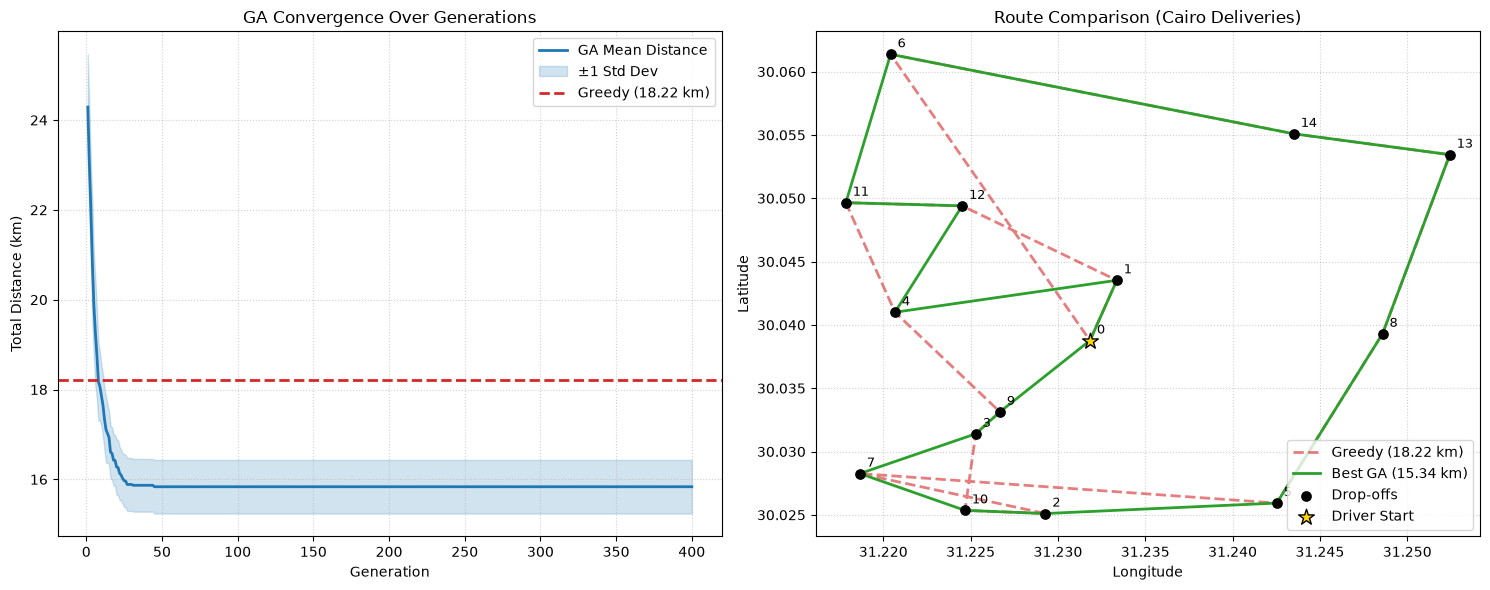

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left plot: Convergence over generations
mean_hist = np.mean(ga_histories, axis=0)
std_hist = np.std(ga_histories, axis=0)
gens = range(1, len(mean_hist) + 1)

ax1.plot(gens, mean_hist, label="GA Mean Distance", color="#1f77b4", lw=2)
ax1.fill_between(
    gens,
    mean_hist - std_hist,
    mean_hist + std_hist,
    color="#1f77b4",
    alpha=0.2,
    label="±1 Std Dev",
)
ax1.axhline(
    greedy_dist,
    color="#d62728",
    ls="--",
    lw=2,
    label=f"Greedy ({greedy_dist:.2f} km)",
)
ax1.set_title("GA Convergence Over Generations")
ax1.set_xlabel("Generation")
ax1.set_ylabel("Total Distance (km)")
ax1.legend()
ax1.grid(True, ls=":", alpha=0.6)


# Right plot: Map of the routes
def draw_route(ax, tour, color, style, label, alpha=1.0):
  pts = nodes_df.iloc[tour + [tour[0]]]
  ax.plot(
      pts["lon"], pts["lat"], ls=style, color=color, lw=2, alpha=alpha, label=label
  )


draw_route(
    ax2, greedy_tour, "#d62728", "--", f"Greedy ({greedy_dist:.2f} km)", alpha=0.6
)
draw_route(
    ax2, best_ga_tour, "#2ca02c", "-", f"Best GA ({best_ga_dist:.2f} km)"
)

ax2.scatter(
    nodes_df["lon"][1:],
    nodes_df["lat"][1:],
    color="black",
    zorder=5,
    s=45,
    label="Drop-offs",
)
ax2.scatter(
    nodes_df["lon"][0],
    nodes_df["lat"][0],
    color="gold",
    edgecolors="black",
    zorder=6,
    s=140,
    marker="*",
    label="Driver Start",
)

for _, row in nodes_df.iterrows():
  ax2.annotate(
      f"{row['ID']}",
      (row["lon"], row["lat"]),
      textcoords="offset points",
      xytext=(5, 5),
      fontsize=9,
  )

ax2.set_title(f"Route Comparison ({SELECTED_CITY} Deliveries)")
ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")
ax2.legend(loc="lower right")
ax2.grid(True, ls=":", alpha=0.6)

plt.tight_layout()
plt.show()

*Step 6: Experiments on 10 delivery batches*

The 15-stop benchmark above uses only one set of stops, so a good result could be luck of that particular instance. Here we build 10 delivery batches from the dataset and run the GA on each one with 10 different seeds.

* **Batches:** Cairo orders placed on 2 June 2025, one batch per hour from 08:00 to 17:00. Cancelled orders are removed (they need no delivery) and the rest are taken in order-time order. The data is synthetic, so the hour is only a label: each batch is effectively a different random set of stops, and differences between batches say nothing about time of day.
* **Hub (Node 0):** the centre of the Cairo delivery area (the average customer location). Every route starts and ends there, like a courier leaving a dark store or depot.
* **Experiment A, hub + 9 drop-offs:** small enough for brute force, so we know the true shortest route and can measure how close the GA gets.
* **Experiment B:** measured brute-force time for 6 to 11 stops, used to estimate bigger sizes.
* **Experiment C, hub + 20 drop-offs:** too big for brute force, so the GA is compared with greedy.

The GA keeps its default settings (population 120, 400 generations) in every experiment. Standard deviations in this step are sample standard deviations (pandas `std`, ddof=1). Run times depend on the computer, so only compare times from the same run of the notebook. All tables and figures are saved to the `results/` folder.

In [6]:
import math
import os

# Experiment settings
BATCH_DATE = "2025-06-02"
BATCH_HOURS = range(8, 18)  # 08:00 to 17:00 -> 10 batches
SMALL_DROPOFFS = 9  # hub + 9 = 10 stops, brute force still takes only seconds
LARGE_DROPOFFS = 20  # hub + 20 = 21 stops, brute force is impossible
NUM_SEEDS = 10  # GA runs per batch, seeds SEED to SEED + 9

os.makedirs("results", exist_ok=True)

orders = raw_df[raw_df["City"] == SELECTED_CITY].copy()
orders["Order_Time"] = pd.to_datetime(orders["Order_Time"])

# Hub = centre of the city's delivery area (average customer location)
hub = (orders["Customer_Lat"].mean(), orders["Customer_Lon"].mean())


def build_matrix(points):
  # Same haversine distance matrix as Step 1, for any list of (lat, lon) points
  size = len(points)
  matrix = np.zeros((size, size))
  for i in range(size):
    for j in range(size):
      if i != j:
        matrix[i][j] = haversine(
            points[i][0], points[i][1], points[j][0], points[j][1]
        )
  return matrix


batches = []
for hour in BATCH_HOURS:
  window = orders[
      (orders["Order_Time"].dt.strftime("%Y-%m-%d") == BATCH_DATE)
      & (orders["Order_Time"].dt.hour == hour)
      & (orders["Order_Status"] != "Cancelled")
  ].sort_values(["Order_Time", "Order_ID"])
  assert len(window) >= LARGE_DROPOFFS, f"only {len(window)} orders at {hour}:00"

  drops = list(zip(window["Customer_Lat"], window["Customer_Lon"]))
  batches.append({
      "name": f"{hour:02d}:00",
      "orders_in_hour": len(window),
      "points": [hub] + drops[:LARGE_DROPOFFS],
  })

print(f"Hub (Node 0): {hub[0]:.4f}, {hub[1]:.4f}")
for b in batches:
  print(f"Batch {b['name']}: {b['orders_in_hour']} non-cancelled orders in that hour")

Hub (Node 0): 30.0444, 31.2358
Batch 08:00: 37 non-cancelled orders in that hour
Batch 09:00: 29 non-cancelled orders in that hour
Batch 10:00: 36 non-cancelled orders in that hour
Batch 11:00: 37 non-cancelled orders in that hour
Batch 12:00: 34 non-cancelled orders in that hour
Batch 13:00: 48 non-cancelled orders in that hour
Batch 14:00: 44 non-cancelled orders in that hour
Batch 15:00: 32 non-cancelled orders in that hour
Batch 16:00: 36 non-cancelled orders in that hour
Batch 17:00: 30 non-cancelled orders in that hour


In [7]:
# Experiment A: how close does the GA get to the true shortest route?
small_rows = []
for b in batches:
  matrix = build_matrix(b["points"][: SMALL_DROPOFFS + 1])
  _, opt_dist, bf_time = brute_force_tsp(matrix)
  _, gr_dist, _ = greedy_tsp(matrix)

  for s in range(NUM_SEEDS):
    random.seed(SEED + s)
    np.random.seed(SEED + s)
    _, ga_dist, _, ga_time = run_genetic_algorithm(matrix)
    small_rows.append({
        "batch": b["name"],
        "seed": SEED + s,
        "optimum_km": opt_dist,
        "greedy_km": gr_dist,
        "ga_km": ga_dist,
        "greedy_gap_pct": 100 * (gr_dist - opt_dist) / opt_dist,
        "ga_gap_pct": 100 * (ga_dist - opt_dist) / opt_dist,
        "ga_found_optimum": ga_dist <= opt_dist + 1e-9,
        "bf_time_s": bf_time,
        "ga_time_s": ga_time,
    })

small_runs = pd.DataFrame(small_rows)
small_summary = small_runs.groupby("batch").agg(
    optimum_km=("optimum_km", "first"),
    greedy_gap_pct=("greedy_gap_pct", "first"),
    ga_mean_gap_pct=("ga_gap_pct", "mean"),
    ga_worst_gap_pct=("ga_gap_pct", "max"),
    ga_exact_optimum_pct=("ga_found_optimum", "mean"),
    bf_time_s=("bf_time_s", "first"),
    ga_mean_time_s=("ga_time_s", "mean"),
).reset_index()
small_summary["ga_exact_optimum_pct"] *= 100

small_runs.to_csv("results/expA_ga_vs_optimum_runs.csv", index=False)
small_summary.to_csv("results/expA_ga_vs_optimum_summary.csv", index=False)

print(f"--- Experiment A: {SMALL_DROPOFFS + 1}-stop batches, {NUM_SEEDS} GA runs each ---")
print(small_summary.round(3).to_string(index=False))

found = small_runs["ga_found_optimum"]
print(
    f"\nGA found the exact optimum in {found.sum()} of {len(found)} runs"
    f" ({found.mean() * 100:.0f}%)."
)
print(
    f"Mean gap to the optimum: GA {small_runs['ga_gap_pct'].mean():.2f}%"
    f" (worst run {small_runs['ga_gap_pct'].max():.2f}%),"
    f" greedy {small_summary['greedy_gap_pct'].mean():.2f}%."
)
worse = (small_runs["ga_km"] > small_runs["greedy_km"] + 1e-9).sum()
print(f"GA route was longer than greedy's in {worse} of {len(small_runs)} runs.")

--- Experiment A: 10-stop batches, 10 GA runs each ---
batch  optimum_km  greedy_gap_pct  ga_mean_gap_pct  ga_worst_gap_pct  ga_exact_optimum_pct  bf_time_s  ga_mean_time_s
08:00      10.812          14.886            0.023             0.231                  90.0      0.792           0.441
09:00      10.561           3.091            0.000             0.000                 100.0      0.803           0.447
10:00      10.415           2.267            0.039             0.131                  70.0      0.763           0.446
11:00      12.369           6.870            0.000             0.000                 100.0      0.775           0.451
12:00      11.398           1.465            0.728             5.622                  80.0      0.791           0.455
13:00      14.550          10.209            0.051             0.102                  50.0      0.786           0.447
14:00      12.886           1.015            1.737             8.684                  80.0      0.803           0.501
1

In [8]:
# Experiment B: measured brute-force time as the number of stops grows
bf_rows = []
for stops in range(6, 12):  # 6 to 11 stops, hub included
  matrix = build_matrix(batches[0]["points"][:stops])
  _, _, bf_time = brute_force_tsp(matrix)
  bf_rows.append({
      "stops": stops,
      "routes_checked": math.factorial(stops - 1),
      "time_s": bf_time,
  })

bf_times = pd.DataFrame(bf_rows)
bf_times["us_per_route"] = 1e6 * bf_times["time_s"] / bf_times["routes_checked"]
bf_times.to_csv("results/expB_bruteforce_times.csv", index=False)


def readable(seconds):
  # Show a number of seconds in the biggest unit that fits
  units = [("years", 365 * 24 * 3600), ("days", 24 * 3600), ("hours", 3600), ("minutes", 60)]
  for unit, size in units:
    if seconds >= size:
      return f"{seconds / size:,.1f} {unit}"
  return f"{seconds:.2f} seconds"


print("--- Experiment B: measured brute-force time ---")
print(bf_times.round(3).to_string(index=False))

# Each extra stop multiplies the number of routes, so bigger sizes are estimated
# from the time per route measured at 11 stops. The time per route still grows a
# little with more stops (see us_per_route), so these estimates are lower bounds.
sec_per_route = bf_times["time_s"].iloc[-1] / bf_times["routes_checked"].iloc[-1]
print("\nEstimated brute-force time on this machine (lower bounds):")
for stops in [15, 21]:
  routes = math.factorial(stops - 1)
  print(f"  {stops} stops: {routes:,} routes -> at least {readable(sec_per_route * routes)}")

--- Experiment B: measured brute-force time ---
 stops  routes_checked  time_s  us_per_route
     6             120   0.000         2.088
     7             720   0.002         2.565
     8            5040   0.011         2.118
     9           40320   0.093         2.307
    10          362880   1.034         2.849
    11         3628800  10.880         2.998

Estimated brute-force time on this machine (lower bounds):
  15 stops: 87,178,291,200 routes -> at least 3.0 days
  21 stops: 2,432,902,008,176,640,000 routes -> at least 231,307.7 years


In [9]:
# Experiment C: GA vs greedy on 21-stop batches (too big for brute force)
large_rows = []
for b in batches:
  matrix = build_matrix(b["points"])
  _, gr_dist, gr_time = greedy_tsp(matrix)

  for s in range(NUM_SEEDS):
    random.seed(SEED + s)
    np.random.seed(SEED + s)
    _, ga_dist, _, ga_time = run_genetic_algorithm(matrix)
    large_rows.append({
        "batch": b["name"],
        "seed": SEED + s,
        "greedy_km": gr_dist,
        "ga_km": ga_dist,
        "saving_km": gr_dist - ga_dist,
        "saving_pct": 100 * (gr_dist - ga_dist) / gr_dist,
        "ga_beats_greedy": ga_dist < gr_dist - 1e-9,
        "greedy_time_s": gr_time,
        "ga_time_s": ga_time,
    })

large_runs = pd.DataFrame(large_rows)
large_summary = large_runs.groupby("batch").agg(
    greedy_km=("greedy_km", "first"),
    ga_mean_km=("ga_km", "mean"),
    ga_sample_std_km=("ga_km", "std"),  # pandas std = sample standard deviation (ddof=1)
    ga_best_km=("ga_km", "min"),
    mean_saving_pct=("saving_pct", "mean"),
    ga_win_pct=("ga_beats_greedy", "mean"),
    ga_mean_time_s=("ga_time_s", "mean"),
).reset_index()
large_summary["ga_win_pct"] *= 100

large_runs.to_csv("results/expC_ga_vs_greedy_runs.csv", index=False)
large_summary.to_csv("results/expC_ga_vs_greedy_summary.csv", index=False)

print(f"--- Experiment C: {LARGE_DROPOFFS + 1}-stop batches, {NUM_SEEDS} GA runs each ---")
print(large_summary.round(3).to_string(index=False))

saving = large_runs["saving_pct"]
diff = large_runs["ga_km"] - large_runs["greedy_km"]
wins = (diff < -1e-9).sum()
ties = (diff.abs() <= 1e-9).sum()
losses = (diff > 1e-9).sum()
batch_wins = (large_summary["ga_mean_km"] < large_summary["greedy_km"]).sum()
print(
    f"\nAverage saving over greedy: {saving.mean():.1f}% (range {saving.min():.1f}%"
    f" to {saving.max():.1f}%) over {len(saving)} runs."
)
print(
    f"Spread: sample std {saving.std():.1f}% over all runs (mostly differences between"
    f" batches); {large_runs.groupby('batch')['saving_pct'].std().mean():.1f}% on average"
    f" between the {NUM_SEEDS} seeds of one batch."
)
print(
    f"GA vs greedy: {wins} wins, {ties} ties (same route length), {losses} losses."
    f" The GA's average route was shorter in {batch_wins} of {len(large_summary)} batches."
)
print(
    f"Average run time: GA {large_runs['ga_time_s'].mean():.2f} s,"
    f" greedy {large_runs['greedy_time_s'].mean():.5f} s."
)

--- Experiment C: 21-stop batches, 10 GA runs each ---
batch  greedy_km  ga_mean_km  ga_sample_std_km  ga_best_km  mean_saving_pct  ga_win_pct  ga_mean_time_s
08:00     16.124      15.455             0.305      14.988            4.149       100.0           0.854
09:00     15.560      14.205             0.373      14.008            8.709       100.0           0.848
10:00     18.748      17.910             0.874      17.252            4.469        80.0           0.851
11:00     17.216      15.375             0.697      14.835           10.694       100.0           0.898
12:00     14.624      14.271             0.255      14.138            2.417        80.0           0.954
13:00     21.234      18.734             0.349      18.088           11.776       100.0           0.950
14:00     21.048      17.252             0.349      16.607           18.036       100.0           0.937
15:00     16.803      17.125             0.369      16.803           -1.915         0.0           0.934
16:00    

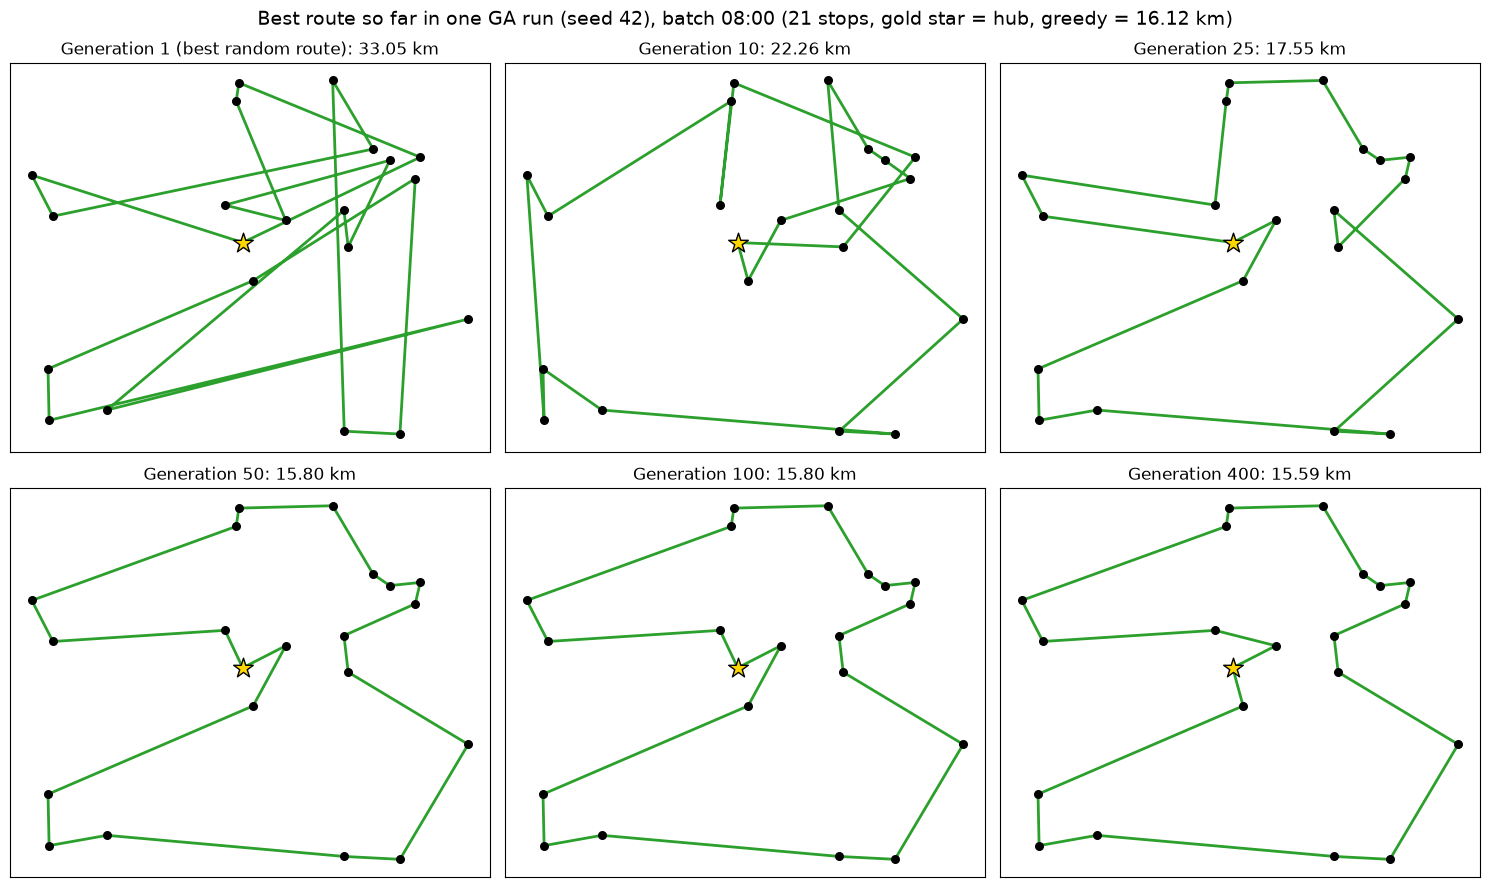

In [10]:
# Brief step 5: how the best route improves over the generations (first 21-stop batch).
# The GA is seeded, so running it for g generations with the same seed gives exactly
# the best route that the full 400-generation run had reached by generation g.
demo = batches[0]
demo_matrix = build_matrix(demo["points"])
demo_pts = np.array(demo["points"])
snapshot_gens = [1, 10, 25, 50, 100, 400]

# One full run first: history[g - 1] is its best distance after generation g
random.seed(SEED)
np.random.seed(SEED)
_, _, full_history, _ = run_genetic_algorithm(demo_matrix)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, gens in zip(axes.flat, snapshot_gens):
  random.seed(SEED)
  np.random.seed(SEED)
  tour, dist, _, _ = run_genetic_algorithm(demo_matrix, generations=gens)
  assert abs(dist - full_history[gens - 1]) < 1e-9  # same as the full run at generation g
  route = demo_pts[tour + [tour[0]]]

  ax.plot(route[:, 1], route[:, 0], "-", color="#2ca02c", lw=2)
  ax.scatter(demo_pts[1:, 1], demo_pts[1:, 0], color="black", s=30, zorder=5)
  ax.scatter(
      demo_pts[0, 1], demo_pts[0, 0],
      color="gold", edgecolors="black", marker="*", s=220, zorder=6,
  )
  note = " (best random route)" if gens == 1 else ""
  ax.set_title(f"Generation {gens}{note}: {dist:.2f} km")
  ax.set_xticks([])
  ax.set_yticks([])

demo_greedy = large_summary.loc[large_summary["batch"] == demo["name"], "greedy_km"].iloc[0]
fig.suptitle(
    f"Best route so far in one GA run (seed {SEED}), batch {demo['name']}"
    f" ({len(demo_pts)} stops, gold star = hub, greedy = {demo_greedy:.2f} km)",
    fontsize=14,
)
plt.tight_layout()
plt.savefig("results/route_over_generations.png", dpi=150)
plt.show()

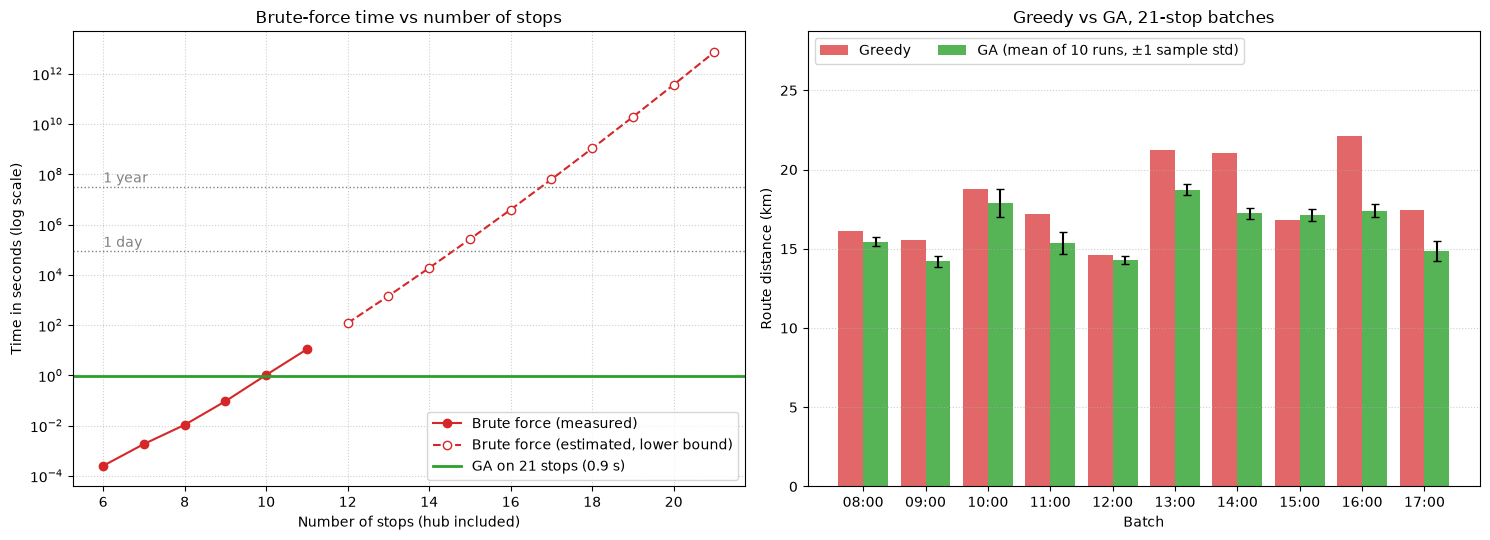

In [11]:
# Summary figure: why brute force fails, and how the GA compares with greedy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: brute-force time grows factorially with the number of stops (log scale)
est_stops = list(range(12, LARGE_DROPOFFS + 2))
est_times = [sec_per_route * math.factorial(s - 1) for s in est_stops]
ax1.semilogy(bf_times["stops"], bf_times["time_s"], "o-", color="#d62728", label="Brute force (measured)")
ax1.semilogy(est_stops, est_times, "o--", color="#d62728", mfc="white", label="Brute force (estimated, lower bound)")
ax1.axhline(
    large_runs["ga_time_s"].mean(), color="#2ca02c", lw=2,
    label=f"GA on {LARGE_DROPOFFS + 1} stops ({large_runs['ga_time_s'].mean():.1f} s)",
)
for label, seconds in [("1 day", 24 * 3600), ("1 year", 365 * 24 * 3600)]:
  ax1.axhline(seconds, color="gray", ls=":", lw=1)
  ax1.text(6, seconds * 1.5, label, color="gray")
ax1.set_xlabel("Number of stops (hub included)")
ax1.set_ylabel("Time in seconds (log scale)")
ax1.set_title("Brute-force time vs number of stops")
ax1.legend(loc="lower right")
ax1.grid(True, which="major", ls=":", alpha=0.6)

# Right: greedy vs GA on each 21-stop batch
x = np.arange(len(large_summary))
ax2.bar(x - 0.2, large_summary["greedy_km"], 0.4, color="#d62728", alpha=0.7, label="Greedy")
ax2.bar(
    x + 0.2, large_summary["ga_mean_km"], 0.4, yerr=large_summary["ga_sample_std_km"],
    capsize=3, color="#2ca02c", alpha=0.8, label=f"GA (mean of {NUM_SEEDS} runs, ±1 sample std)",
)
ax2.set_xticks(x)
ax2.set_xticklabels(large_summary["batch"])
ax2.set_xlabel("Batch")
ax2.set_ylabel("Route distance (km)")
ax2.set_title(f"Greedy vs GA, {LARGE_DROPOFFS + 1}-stop batches")
ax2.set_ylim(0, large_summary["greedy_km"].max() * 1.3)  # headroom for the legend
ax2.legend(loc="upper left", ncol=2)
ax2.grid(True, axis="y", ls=":", alpha=0.6)

plt.tight_layout()
plt.savefig("results/experiment_summary.png", dpi=150)
plt.show()